In [67]:
#imports

import sys
!{sys.executable} -m pip install folium

import numpy as np
import folium
from folium.plugins import MarkerCluster
import pandas as pd
import csv
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn import tree
from matplotlib import colors as mpl_colors
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


In [68]:
#Task 1 - reading in the data from the csv file into a data frame

lines = [] # a basic list for our lines

with open("data.csv", "r") as file:
    spamreader = csv.reader(file, delimiter=',') #we read in the content of the cvs, fields separated by a comma
    for row in spamreader: #each row gets attached to the list of lines
        lines.append(row)

var_names = np.array(lines[0], dtype=object) #the names of the columns as a numpy array for later use

lines_with_data_types = []

for line in lines[1:]:
    lines_with_data_types.append([float(line[0]),float(line[1]),line[2], line[3], float(line[4]), float(line[5]), float(line[6])])


df_with_types = pd.DataFrame(lines_with_data_types, columns=var_names)
df_with_types.head()

,Geographical Location (Latitude),Geographical Location (Longitude),State of Sewage System,Sampling Date,Nitrogen (mg/L),Phosphorus (mg/L),Population
0,42.867278,-107.997678,Moderate,2015-09-30,5.447159,4.634808,923253.0
1,34.337029,-104.681197,Good,2020-01-29,9.087964,3.129082,1196631.0
2,34.831615,-93.134004,Moderate,2017-09-09,0.485658,4.545678,781628.0
3,45.463162,-120.709056,Poor,2019-11-12,2.666448,4.090627,855275.0
4,41.444474,-99.464055,Moderate,2016-08-19,8.425540,1.247981,1019428.0


In [69]:
# Task 2 - looking at what types of data our dataframe contains

df_with_types.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 7 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Geographical Location (Latitude)   412 non-null    float64
 1   Geographical Location (Longitude)  412 non-null    float64
 2   State of Sewage System             412 non-null    object 
 3   Sampling Date                      412 non-null    object 
 4   Nitrogen (mg/L)                    412 non-null    float64
 5   Phosphorus (mg/L)                  412 non-null    float64
 6   Population                         412 non-null    float64
dtypes: float64(5), object(2)
memory usage: 22.7+ KB


In [70]:
# Task 3 - Converting to date-time format, searching for missing values

column_names = df_with_types.columns.tolist()

df_with_types[var_names[3]] = pd.to_datetime(df_with_types[var_names[3]])
df_with_types.info()

print(f"\nThere number of missing values in this dataframe: \n\n{df_with_types.isnull().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 7 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Geographical Location (Latitude)   412 non-null    float64       
 1   Geographical Location (Longitude)  412 non-null    float64       
 2   State of Sewage System             412 non-null    object        
 3   Sampling Date                      412 non-null    datetime64[ns]
 4   Nitrogen (mg/L)                    412 non-null    float64       
 5   Phosphorus (mg/L)                  412 non-null    float64       
 6   Population                         412 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 22.7+ KB

There number of missing values in this dataframe: 

Geographical Location (Latitude)     0
Geographical Location (Longitude)    0
State of Sewage System               0
Sampling Date  

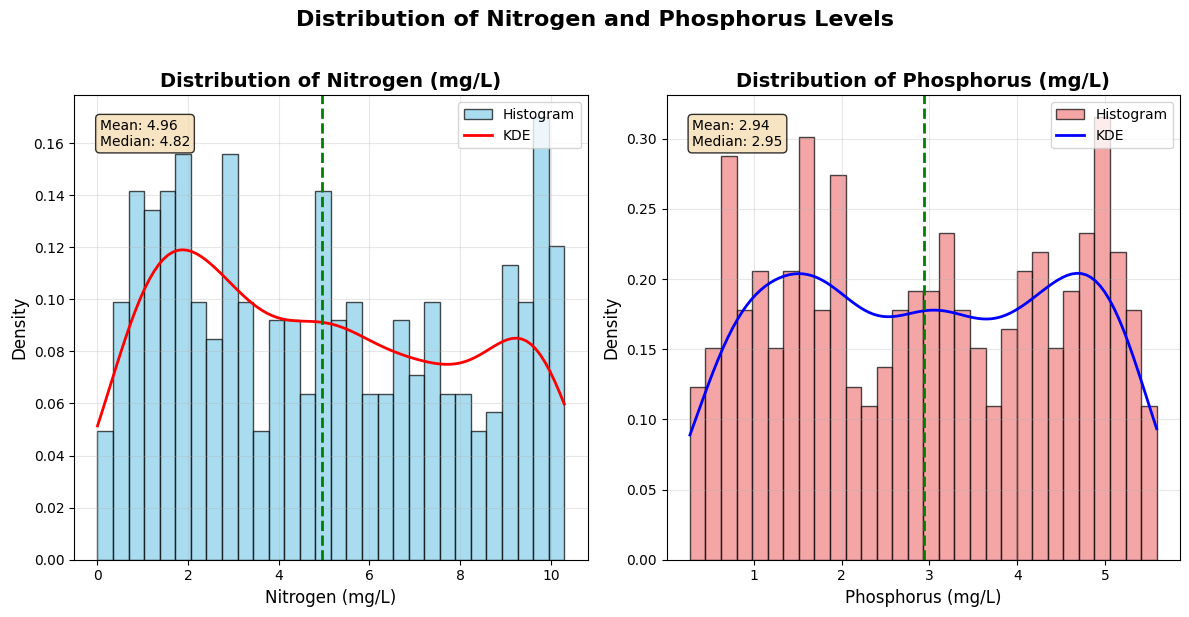

In [71]:
# Task 4/a - Visualization of data before processing with histogram

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

col1 = var_names[4]

nitrogen_data = df_with_types[col1].dropna()

# Histogram
n, bins, patches = ax1.hist(nitrogen_data, bins=30, alpha=0.7,
                            color='skyblue', edgecolor='black',
                            density=True, label='Histogram')

# Adding KDE
if len(nitrogen_data) > 1:
    kde = gaussian_kde(nitrogen_data)
    x_range = np.linspace(nitrogen_data.min(), nitrogen_data.max(), 100)
    ax1.plot(x_range, kde(x_range), 'r-', linewidth=2, label='KDE')

ax1.set_xlabel(f'{col1}', fontsize=12)
ax1.set_ylabel('Density', fontsize=12)
ax1.set_title(f'Distribution of {col1}', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Adding statistics text
mean_val = nitrogen_data.mean()
median_val = nitrogen_data.median()
ax1.axvline(mean_val, color='green', linestyle='--', linewidth=2)
ax1.text(0.05, 0.95, f'Mean: {mean_val:.2f}\nMedian: {median_val:.2f}',
         transform=ax1.transAxes, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))



col2 = var_names[5]
phosphorus_data = df_with_types[col2].dropna()

n, bins, patches = ax2.hist(phosphorus_data, bins=30, alpha=0.7,
                            color='lightcoral', edgecolor='black',
                            density=True, label='Histogram')

# Adding KDE for Phosphorus as well
from scipy.stats import gaussian_kde
if len(phosphorus_data) > 1:
    kde = gaussian_kde(phosphorus_data)
    x_range = np.linspace(phosphorus_data.min(), phosphorus_data.max(), 100)
    ax2.plot(x_range, kde(x_range), 'b-', linewidth=2, label='KDE')

ax2.set_xlabel(f'{col2}', fontsize=12)
ax2.set_ylabel('Density', fontsize=12)
ax2.set_title(f'Distribution of {col2}', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Adding statistics text for Phosphorus
mean_val = phosphorus_data.mean()
median_val = phosphorus_data.median()
ax2.axvline(mean_val, color='green', linestyle='--', linewidth=2)
ax2.text(0.05, 0.95, f'Mean: {mean_val:.2f}\nMedian: {median_val:.2f}',
         transform=ax2.transAxes, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle('Distribution of Nitrogen and Phosphorus Levels',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

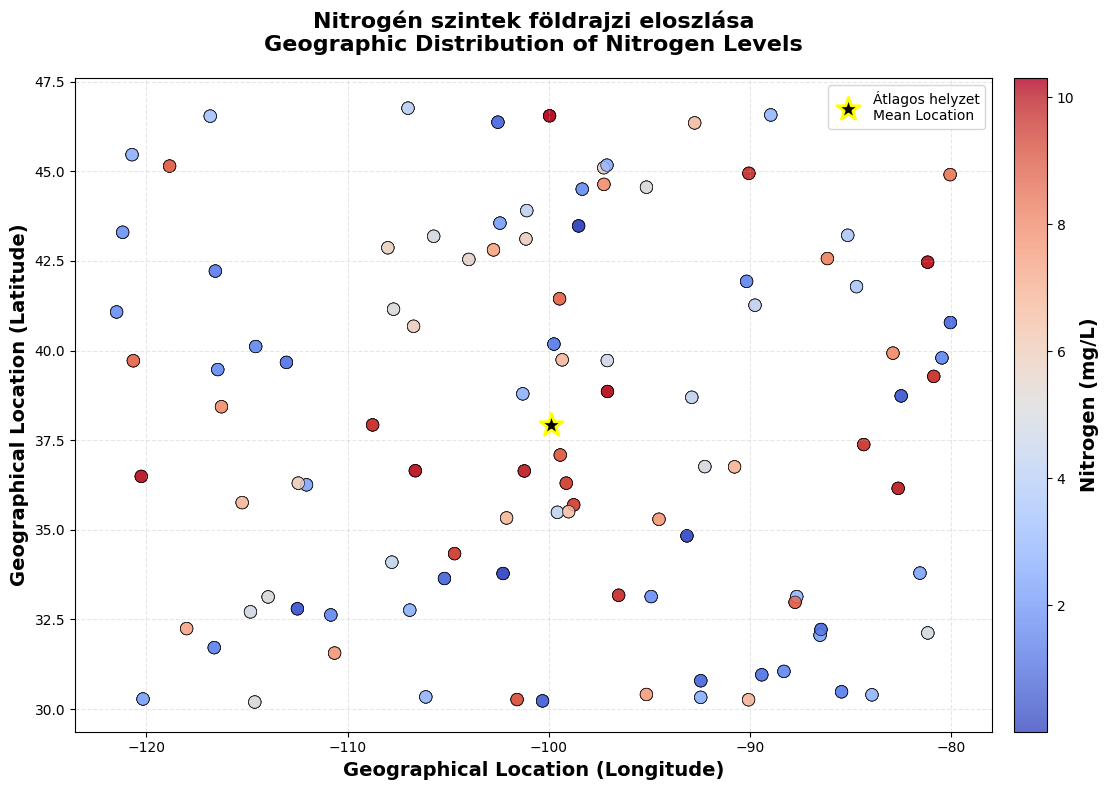


Nitrogen Statistics:
  Min: 0.00 mg/L
  Max: 10.29 mg/L
  Mean: 4.96 mg/L
  Std: 3.10 mg/L


In [72]:
# Task 4/b - Nitrogen scatter plot

# Create the scatter plot
plt.figure(figsize=(12, 8))

# Get data
x = df_with_types[var_names[1]]
y = df_with_types[var_names[0]]
colors = df_with_types[col1]

# Create scatter plot with 'coolwarm' colormap
scatter = plt.scatter(x, y,
                     c=colors,           # Color based on Nitrogen values
                     cmap='coolwarm',    # Coolwarm color palette
                     alpha=0.8,          # Slight transparency
                     s=80,               # Marker size
                     edgecolor='black',  # Black outline
                     linewidth=0.5)      # Outline thickness

# Add colorbar with label
cbar = plt.colorbar(scatter, pad=0.02)
cbar.set_label(f'{col1}', fontsize=14, fontweight='bold')

# Set axis labels
plt.xlabel(f'{var_names[1]}', fontsize=14, fontweight='bold')
plt.ylabel(f'{var_names[0]}', fontsize=14, fontweight='bold')

# Set title
plt.title('Nitrogén szintek földrajzi eloszlása\nGeographic Distribution of Nitrogen Levels',
          fontsize=16, fontweight='bold', pad=20)

# Add grid
plt.grid(True, alpha=0.3, linestyle='--')

# Optional: Add mean location marker
mean_x = x.mean()
mean_y = y.mean()
plt.scatter(mean_x, mean_y, color='black', marker='*',
           s=300, linewidth=2, label='Átlagos helyzet\nMean Location',
           edgecolor='yellow', zorder=5)

# Add legend
plt.legend(loc='upper right', fontsize=10)

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

# Print statistics
print(f"\nNitrogen Statistics:")
print(f"  Min: {df_with_types[col1].min():.2f} mg/L")
print(f"  Max: {df_with_types[col1].max():.2f} mg/L")
print(f"  Mean: {df_with_types[col1].mean():.2f} mg/L")
print(f"  Std: {df_with_types[col1].std():.2f} mg/L")

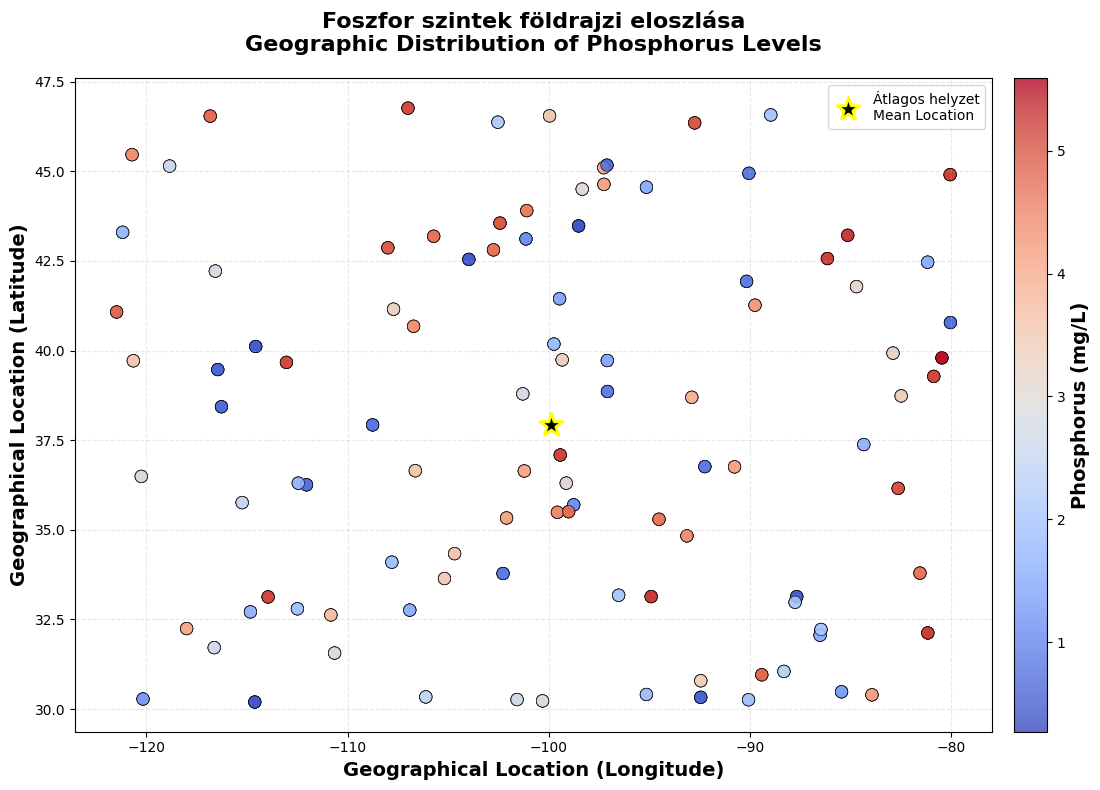


Phosphorus Statistics:
  Min: 0.27 mg/L
  Max: 5.59 mg/L
  Mean: 2.94 mg/L
  Std: 1.54 mg/L


In [73]:
# Task 4/c - Phosphor scatter plot

# Create the scatter plot
plt.figure(figsize=(12, 8))

# Get data
x = df_with_types[var_names[1]]
y = df_with_types[var_names[0]]
colors = df_with_types[col2]

# Create scatter plot with 'coolwarm' colormap
scatter = plt.scatter(x, y,
                     c=colors,           # Color based on Phosphorus values
                     cmap='coolwarm',    # Coolwarm color palette
                     alpha=0.8,          # Slight transparency
                     s=80,               # Marker size
                     edgecolor='black',  # Black outline
                     linewidth=0.5)      # Outline thickness

# Add colorbar with label
cbar = plt.colorbar(scatter, pad=0.02)
cbar.set_label(f'{col2}', fontsize=14, fontweight='bold')

# Set axis labels
plt.xlabel(f'{var_names[1]}', fontsize=14, fontweight='bold')
plt.ylabel(f'{var_names[0]}', fontsize=14, fontweight='bold')

# Set title
plt.title('Foszfor szintek földrajzi eloszlása\nGeographic Distribution of Phosphorus Levels',
          fontsize=16, fontweight='bold', pad=20)

# Add grid
plt.grid(True, alpha=0.3, linestyle='--')

# Optional: Add mean location marker
mean_x = x.mean()
mean_y = y.mean()
plt.scatter(mean_x, mean_y, color='black', marker='*',
           s=300, linewidth=2, label='Átlagos helyzet\nMean Location',
           edgecolor='yellow', zorder=5)

# Add legend
plt.legend(loc='upper right', fontsize=10)

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

# Print statistics
print(f"\nPhosphorus Statistics:")
print(f"  Min: {df_with_types[col2].min():.2f} mg/L")
print(f"  Max: {df_with_types[col2].max():.2f} mg/L")
print(f"  Mean: {df_with_types[col2].mean():.2f} mg/L")
print(f"  Std: {df_with_types[col2].std():.2f} mg/L")

In [74]:
# Task 5 - Visualize Nitrogen levels on an interactable map

# suggested code from the assigment ot determine color
max_N = round(df_with_types[col1].max())
print(f"Maximum nitrogén szint (kerekítve): {max_N}")

levels = range(max_N + 1)
color_list = list(mpl_colors.cnames.values())[0:-1:10]
color_dict = dict(zip(levels, list(mpl_colors.cnames.values())[0:-1:10]))

# determining color based on N levels
def get_color_for_nitrogen(nitrogen_level):
    level = int(round(nitrogen_level))
    level = max(0, min(level, max_N))
    return color_dict[level]

# Determining how to center map based on coordinate means
center_lat = df_with_types[var_names[0]].mean()
center_lon = df_with_types[var_names[1]].mean()

print(f"Térkép központja: ({center_lat:.4f}, {center_lon:.4f})")

# Making the map object
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=4,
    tiles='OpenStreetMap'
)

# Adding a title
title_html = '''
<h3 align="center" style="font-size:16px"><b>Nitrogén szintek (mg/L) a vízmintákban - USA</b></h3>
'''
m.get_root().html.add_child(folium.Element(title_html))

# MarkerCluster for better performance
marker_cluster = MarkerCluster().add_to(m)

# Markers for every spot
for idx, row in df_with_types.iterrows():
    # Coordinates
    lat = row[var_names[0]]
    lon = row[var_names[1]]

    # N color and level
    nitrogen = row[col1]
    phosphorus = row[col2]
    color = get_color_for_nitrogen(nitrogen)

    # Popup content
    popup_content = f"""
    <div style="font-family: Arial, sans-serif; font-size: 12px;">
        <b>Koordináták:</b> {lat:.4f}, {lon:.4f}<br>
        <b>Nitrogén (N):</b> {nitrogen:.2f} mg/L<br>
        <b>Foszfor (P):</b> {phosphorus:.2f} mg/L<br>
        <b>Csatornarendszer:</b> {row[var_names[2]]}<br>
        <b>Mintavétel dátuma:</b> {row[var_names[3]].strftime('%Y-%m-%d')}
    </div>
    """

    # CircleMarker with color coded Nitrogen levels
    folium.CircleMarker(
        location=[lat, lon],
        radius=7,
        popup=folium.Popup(popup_content, max_width=300),
        color='black',
        fill=True,
        fill_color=color,
        fill_opacity=0.7,
        weight=1
    ).add_to(marker_cluster)

# Legend
legend_html = f'''
<div style="position: fixed;
            bottom: 50px; left: 50px; width: 220px; height: auto;
            background-color: white; border:2px solid grey; z-index:9999;
            font-size:12px; padding: 10px; border-radius: 5px;">
    <b>Nitrogén szintek (mg/L)</b><br><br>
'''

# Dinamic legends
for level in range(max_N + 1):
    marker_color = color_dict[level]
    legend_html += f'''
    <i style="background: {marker_color}; width: 20px; height: 20px;
       display: inline-block; border: 1px solid grey; margin-right: 5px;"></i>
    {level} mg/L<br>
    '''

legend_html += f'''
    <br>
    <b>Összes mintavételi hely:</b> {len(df_with_types)}<br>
</div>
'''

m.get_root().html.add_child(folium.Element(legend_html))

print("Interaktív térkép sikeresen létrehozva!")
print(f"Mintavételi helyek száma: {len(df_with_types)}")

m.save("nitrogen_map.html")
m

Maximum nitrogén szint (kerekítve): 10
Térkép központja: (37.9290, -99.9105)
Interaktív térkép sikeresen létrehozva!
Mintavételi helyek száma: 412


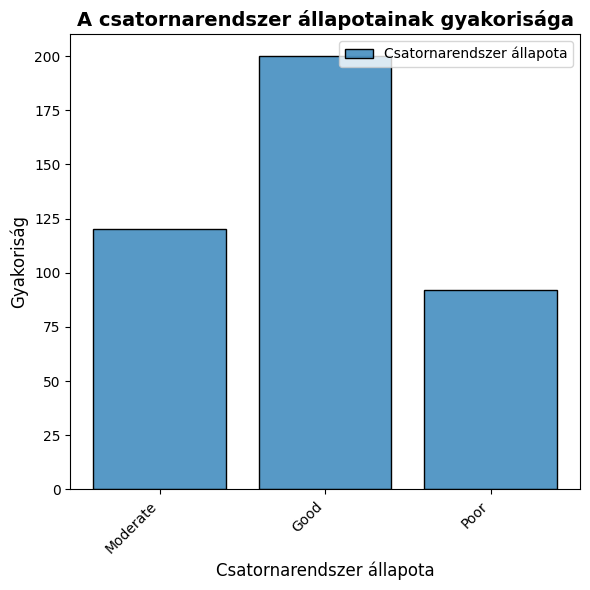

In [75]:
# Task 6 - Frequency diagram on sewage system states

plt.figure(figsize=(6, 6))

# Seaborn histplot
sns.histplot(data=df_with_types, x=var_names[2], discrete=True, shrink=0.8)


plt.title('A csatornarendszer állapotainak gyakorisága', fontsize=14, fontweight='bold')
plt.xlabel('Csatornarendszer állapota', fontsize=12)
plt.ylabel('Gyakoriság', fontsize=12)
plt.legend(['Csatornarendszer állapota'], loc='upper right')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()


plt.show()

N+P oszlop létrehozva:
   Nitrogen (mg/L)  Phosphorus (mg/L)        N+P
0         5.447159           4.634808  10.081967
1         9.087964           3.129082  12.217047
2         0.485658           4.545678   5.031337
3         2.666448           4.090627   6.757075
4         8.425540           1.247981   9.673521


Új numerikus DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 7 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Geographical Location (Latitude)   412 non-null    float64
 1   Geographical Location (Longitude)  412 non-null    float64
 2   Nitrogen (mg/L)                    412 non-null    float64
 3   Phosphorus (mg/L)                  412 non-null    float64
 4   Population                         412 non-null    float64
 5   N+P                                412 non-null    float64
 6   SWS_Encoded                        4

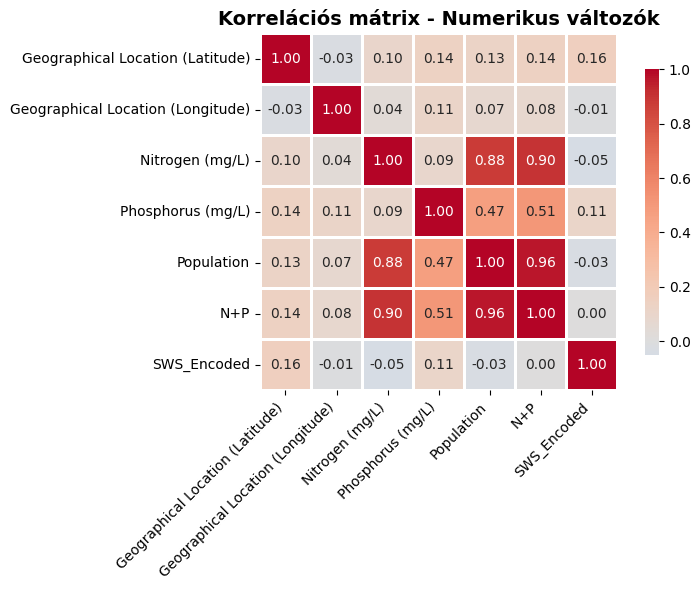

In [76]:
# Task 7 - Heatmap for correlation between sewage system state and elemental content

# c)New DataFrame with only numeric data
df_numeric = df_with_types[[var_names[0], var_names[1], col1, col2, var_names[-1]]].copy()
df_numeric['N+P'] = df_with_types[col1] + df_with_types[col2]

label_encoder = LabelEncoder()
df_numeric['SWS_Encoded'] = label_encoder.fit_transform(df_with_types[var_names[2]])

# Checking results
print("N+P oszlop létrehozva:")
print(df_numeric[[col1, col2, 'N+P']].head())
print("\n")

print("Új numerikus DataFrame:")
df_numeric.info()
print("\n")

print("State of Sewage System kódolása:")
print("Eredeti értékek:", label_encoder.classes_)
print("\nKódolt értékek:")
print(df_numeric[['SWS_Encoded']].head(10))
print("\nÉrtékek megfeleltetése:")
for i, label in enumerate(label_encoder.classes_):
    print(f"{label} -> {i}")
print("\n")


# Correlation matrix with Pearson method
correlation_matrix = df_numeric.corr(method='pearson')

print("Korrelációs mátrix:")
print(correlation_matrix)
print("\n")

# d) Heatmap diagram
plt.figure(figsize=(8, 6))

sns.heatmap(correlation_matrix,
            annot=True,  # correlation metrics showing
            fmt='.2f',   # 2 digits
            cmap='coolwarm',  # coolwarm colormap
            center=0,    # 0 is the middle of the colormap
            square=True,  # cell shape
            linewidths=1,  # lines between cells
            cbar_kws={"shrink": 0.8})  # size of colormap

plt.title('Korrelációs mátrix - Numerikus változók', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [77]:
# Task 8 - renaming columns in the dataframe

df_numeric.rename(columns={
    'Geographical Location (Latitude)': 'Lati',
    'Geographical Location (Longitude)': 'Long',
    'Sampling Date': 'SDate',
    'Nitrogen (mg/L)': 'N',
    'Phosphorus (mg/L)': 'P',
    'State of Sewage System': 'SWS',
    'Population':'Pop'
}, inplace=True)

print("Oszlopnevek az átnevezés után:")
print(df_numeric.columns.tolist())
print(df_with_types.columns.tolist())

Oszlopnevek az átnevezés után:
['Lati', 'Long', 'N', 'P', 'Pop', 'N+P', 'SWS_Encoded']
['Geographical Location (Latitude)', 'Geographical Location (Longitude)', 'State of Sewage System', 'Sampling Date', 'Nitrogen (mg/L)', 'Phosphorus (mg/L)', 'Population']


In [78]:
# Task 9 - Analyzing the new data in the new Data Frame

df_numeric.describe()

,Lati,Long,N,P,Pop,N+P,SWS_Encoded
count,412.000000,412.000000,412.000000,412.000000,4.120000e+02,412.000000,412.000000
mean,37.928978,-99.910523,4.956458,2.941068,9.041799e+05,7.897526,0.737864
std,5.088459,11.689830,3.097449,1.544422,3.163950e+05,3.585622,0.800987
min,30.198108,-121.476341,0.004284,0.272931,2.053480e+05,0.379070,0.000000
25%,33.138387,-107.997678,2.096088,1.593510,6.752212e+05,4.725642,0.000000
50%,37.926803,-99.464055,4.821583,2.951642,8.774995e+05,7.935702,1.000000
75%,42.542049,-90.071769,7.575510,4.327313,1.184369e+06,10.852442,1.000000
max,46.759853,-80.039258,10.294660,5.586694,1.544160e+06,15.538928,2.000000


In [79]:
# Task 10 - Creating a new column for labeling N+P concentration categories

def categorize_quality(n_p_value):
    if n_p_value < 4:
        return 1
    elif n_p_value > 10:
        return 3
    else:
        return 2

# Apply function in use
df_numeric['Q'] = df_numeric['N+P'].apply(categorize_quality)

# Checking results
print("Q (quality) oszlop létrehozva:")
print("="*50)
print(df_numeric[['N', 'P', 'N+P', 'Q']].head(15))
print("\n")

# Detailing results by categories
print("Minták kategóriánként:")
print("-"*50)
print("\nKategória 1 (N+P < 4):")
print(df_numeric[df_numeric['Q'] == 1][['N+P', 'Q']].head())
print("\nKategória 2 (4 <= N+P <= 10):")
print(df_numeric[df_numeric['Q'] == 2][['N+P', 'Q']].head())
print("\nKategória 3 (N+P > 10):")
print(df_numeric[df_numeric['Q'] == 3][['N+P', 'Q']].head())

Q (quality) oszlop létrehozva:
            N         P        N+P  Q
0    5.447159  4.634808  10.081967  3
1    9.087964  3.129082  12.217047  3
2    0.485658  4.545678   5.031337  2
3    2.666448  4.090627   6.757075  2
4    8.425540  1.247981   9.673521  2
5   10.112253  5.307387  15.419639  3
6    8.805643  3.696816  12.502459  3
7    4.561423  4.099250   8.660673  2
8    0.531916  2.657945   3.189861  1
9    8.222581  5.419199  13.641780  3
10   1.501845  5.286694   6.788539  2
11   0.727787  2.180539   2.908326  1
12   9.346093  1.450394  10.796487  3
13   2.112858  1.211815   3.324672  1
14   4.270026  4.323313   8.593339  2


Minták kategóriánként:
--------------------------------------------------

Kategória 1 (N+P < 4):
         N+P  Q
8   3.189861  1
11  2.908326  1
13  3.324672  1
24  3.786963  1
26  2.777528  1

Kategória 2 (4 <= N+P <= 10):
         N+P  Q
2   5.031337  2
3   6.757075  2
4   9.673521  2
7   8.660673  2
10  6.788539  2

Kategória 3 (N+P > 10):
         N+P 

In [80]:
# Task 11 - Printing out the sizes of each category of 'Q'


# Statistics about column Q
print("Q oszlop értékeinek eloszlása:")
print(df_numeric['Q'].value_counts().sort_index())
print("\n")

Q oszlop értékeinek eloszlása:
Q
1     77
2    193
3    142
Name: count, dtype: int64




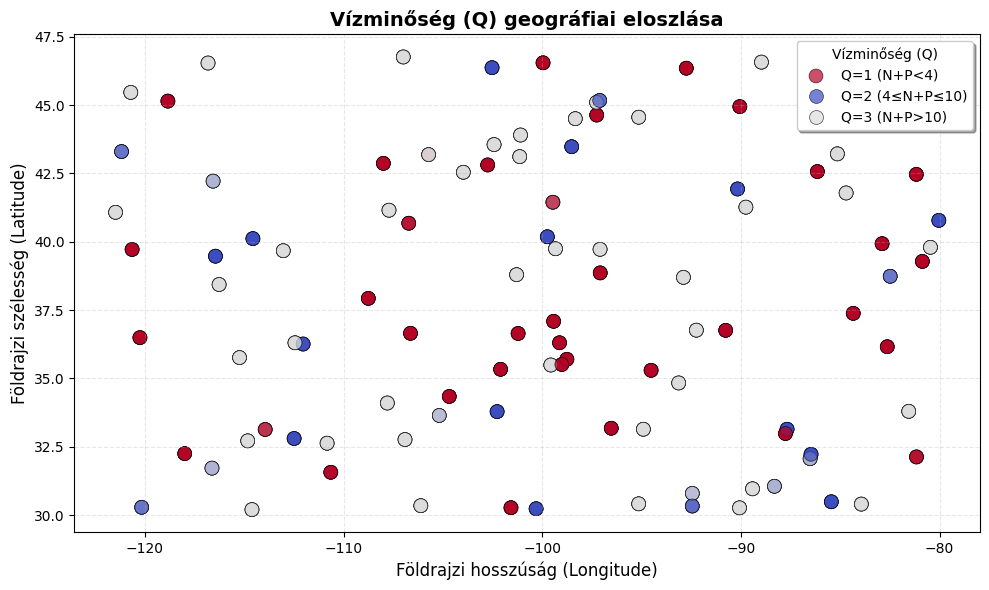

In [81]:
# Task 12 - Geographic distribution of Q values with Seaborn scatterplot

plt.figure(figsize=(10, 6))

# Seaborn scatterplot
sns.scatterplot(data=df_numeric,
                x='Long',  # Longitude
                y='Lati',  # Latitude
                hue='Q',         # coloring by Q values
                palette='coolwarm',
                s=100,           # marker size
                alpha=0.7,
                edgecolor='black',  # marker border
                linewidth=0.5)   # border thickness

# Diagramtitle and labeling
plt.title('Vízminőség (Q) geográfiai eloszlása', fontsize=14, fontweight='bold')
plt.xlabel('Földrajzi hosszúság (Longitude)', fontsize=12)
plt.ylabel('Földrajzi szélesség (Latitude)', fontsize=12)

# Adjusting labels
plt.legend(title='Vízminőség (Q)',
           labels=['Q=1 (N+P<4)', 'Q=2 (4≤N+P≤10)', 'Q=3 (N+P>10)'],
           loc='best',
           frameon=True,
           shadow=True)

# Grid
plt.grid(True, alpha=0.3, linestyle='--')


plt.tight_layout()

plt.show()

In [82]:
# Task 13 - splitting the dataframe to x-es and labels (y)

# we don't need a new data frame, because our numeric one already disincludes dates

y = df_numeric['SWS_Encoded']

# X = all the other numeric data
X = df_numeric[['Lati', 'Long', 'Pop','N', 'P', 'N+P']].copy()

# Checking results
print("Független változók (X):")
print("="*50)
print(X.head())
print(f"\nX shape: {X.shape}")
print("\n")

print("Függő változó (y):")
print("="*50)
print(y.head())
print(f"\ny shape: {y.shape}")
print(f"\ny egyedi értékei: {y.unique()}")
print(f"\ny értékeinek eloszlása:\n{y.value_counts()}")


Független változók (X):
        Lati        Long        Pop         N         P        N+P
0  42.867278 -107.997678   923253.0  5.447159  4.634808  10.081967
1  34.337029 -104.681197  1196631.0  9.087964  3.129082  12.217047
2  34.831615  -93.134004   781628.0  0.485658  4.545678   5.031337
3  45.463162 -120.709056   855275.0  2.666448  4.090627   6.757075
4  41.444474  -99.464055  1019428.0  8.425540  1.247981   9.673521

X shape: (412, 6)


Függő változó (y):
0    1
1    0
2    1
3    2
4    1
Name: SWS_Encoded, dtype: int64

y shape: (412,)

y egyedi értékei: [1 0 2]

y értékeinek eloszlása:
SWS_Encoded
0    200
1    120
2     92
Name: count, dtype: int64


In [ ]:
# Task 14 - Making the data splits, the modell and training it

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                      test_size=0.2,  # 20% test, 80% train
                                                      random_state=42,  # reprodukálhatóság
                                                      stratify=y)  # osztályok arányának megtartása

# Checking results
print("Adatok felosztása:")
print("="*50)
print(f"Teljes adathalmaz: {X.shape[0]} minta")
print(f"Tanító halmaz (X_train): {X_train.shape[0]} minta ({X_train.shape[0]/X.shape[0]*100:.1f}%)")
print(f"Teszt halmaz (X_test): {X_test.shape[0]} minta ({X_test.shape[0]/X.shape[0]*100:.1f}%)")
print("\n")

print("y értékek eloszlása a tanító halmazban:")
print(y_train.value_counts())
print("\n")

print("y értékek eloszlása a teszt halmazban:")
print(y_test.value_counts())
print("\n")

# DecisionTree model
dt_model = DecisionTreeClassifier(random_state=42,
                                   max_depth=5,
                                   min_samples_split=10,
                                   min_samples_leaf=5)

# Training
dt_model.fit(X_train, y_train)

print("Modell sikeresen betanítva!")
print("="*50)
print(f"Fa mélysége: {dt_model.get_depth()}")
print(f"Levelek száma: {dt_model.get_n_leaves()}")
print("\n")

# Visualizing the decision tree
plt.figure(figsize=(12, 8))

tree.plot_tree(dt_model,
               feature_names=X.columns.tolist(),
               class_names = [str(cls) for cls in dt_model.classes_],
               filled=True,  # cololring by class
               rounded=True,  # rounding of the boxes
               fontsize=10)

plt.title('Döntési fa - Csatornarendszer állapot előrejelzése',
          fontsize=14,
          fontweight='bold',
          pad=20)

plt.tight_layout()
plt.show()

Adatok felosztása:
Teljes adathalmaz: 412 minta
Tanító halmaz (X_train): 329 minta (79.9%)
Teszt halmaz (X_test): 83 minta (20.1%)


y értékek eloszlása a tanító halmazban:
SWS_Encoded
0    160
1     96
2     73
Name: count, dtype: int64


y értékek eloszlása a teszt halmazban:
SWS_Encoded
0    40
1    24
2    19
Name: count, dtype: int64


Modell sikeresen betanítva!
Fa mélysége: 5
Levelek száma: 13




In [ ]:
# Task 15 - Prediction, Accuracy, Classification Report and Confusion Matrix

y_pred = dt_model.predict(X_test)

print("Predikció elkészítve a teszt halmazon")
print("="*50)
print(f"Teszt minták száma: {len(y_test)}")
print(f"Predikciók száma: {len(y_pred)}")
print("\n")

accuracy = accuracy_score(y_test, y_pred)
print(f"Modell pontossága (Accuracy): {accuracy:.4f} ({accuracy*100:.2f}%)")
print("\n")

# Report on classes
print("Osztályozási riport:")
print("="*50)
class_report = classification_report(y_test, y_pred,
                                      target_names=[str(cls) for cls in dt_model.classes_])
print(class_report)
print("\n")

#Generating the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Konfúziós mátrix:")
print("="*50)
print(conf_matrix)
print("\n")

# Visualization
plt.figure(figsize=(8, 6))

sns.heatmap(conf_matrix,
            annot=True,  # show values
            fmt='d',  # integer formatting
            cmap='Blues',  # blue palette
            xticklabels=[str(cls) for cls in dt_model.classes_],
            yticklabels=[str(cls) for cls in dt_model.classes_],
            cbar_kws={'label': 'Minták száma'})

plt.title('Konfúziós mátrix - Döntési fa modell', fontsize=14, fontweight='bold')
plt.xlabel('Prediktált osztály', fontsize=12)
plt.ylabel('Valós osztály', fontsize=12)
plt.tight_layout()
plt.show()

# Details
print("Részletes elemzés:")
print("="*50)
print(f"Összes teszt minta: {len(y_test)}")
print(f"Helyesen osztályozott: {(y_test == y_pred).sum()}")
print(f"Helytelenül osztályozott: {(y_test != y_pred).sum()}")
print("\n")

# Accuracy by classes
for cls in dt_model.classes_:
    cls_mask = y_test == cls
    cls_accuracy = (y_test[cls_mask] == y_pred[cls_mask]).sum() / cls_mask.sum()
    print(f"Osztály {cls} pontossága: {cls_accuracy:.4f} ({cls_accuracy*100:.2f}%)")

In [ ]:
# Task 16 - Linear Regression: Population vs N+P pollution level

X_lr = df_numeric[['Pop']].values
y_lr = df_numeric['N+P'].values

# Splitting the data
X_lr_train, X_lr_test, y_lr_train, y_lr_test = train_test_split(
    X_lr, y_lr,
    test_size=0.2,
    random_state=42
)

print("Adatok felosztása:")
print("="*50)
print(f"Tanító halmaz: {X_lr_train.shape[0]} minta ({X_lr_train.shape[0]/len(X_lr)*100:.1f}%)")
print(f"Teszt halmaz: {X_lr_test.shape[0]} minta ({X_lr_test.shape[0]/len(X_lr)*100:.1f}%)")
print("\n")

# Linear regression model
lr_model = LinearRegression()
lr_model.fit(X_lr_train, y_lr_train)

print("Lineáris Regressziós modell sikeresen betanítva!")
print("="*50)
print(f"Meredekség (slope): {lr_model.coef_[0]:.4f}")
print(f"Tengelymetszet (intercept): {lr_model.intercept_:.4f}")
print("\n")

# Prediction on the test split
y_lr_pred = lr_model.predict(X_lr_test)

# Metrics for rate of success
r2 = r2_score(y_lr_test, y_lr_pred)
mse = mean_squared_error(y_lr_test, y_lr_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_lr_test, y_lr_pred)

print("Modell értékelési metrikák:")
print("="*50)
print(f"R² (R-squared): {r2:.4f}")
print(f"MSE (Mean Squared Error): {mse:.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"MAE (Mean Absolute Error): {mae:.4f}")
print("\n")

# Visualization
plt.figure(figsize=(10, 6))

# Test data scatter plot
plt.scatter(X_lr_test, y_lr_test,
           color='blue',
           alpha=0.6,
           s=50,
           label='Teszt adatok',
           edgecolors='black',
           linewidth=0.5)

# Regression linear
plt.plot(X_lr_test, y_lr_pred,
        color='red',
        linewidth=2,
        label=f'Regressziós egyenes (R²={r2:.3f})')

# Diagram title and labels
plt.title('Lineáris regresszió: Population vs N+P szennyezettség',
         fontsize=14,
         fontweight='bold')
plt.xlabel('Population', fontsize=12)
plt.ylabel('N+P szennyezettség (mg/L)', fontsize=12)
plt.legend(loc='best', frameon=True, shadow=True)
plt.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()



In [ ]:
# Task 17 - Prediction on test set and accuracy evaluation

y_lr_pred = lr_model.predict(X_lr_test)

print("Predikció és valós értékek összehasonlítása")
print("="*50)
print("\n")

# First 5 pairs of data
print("Első 5 predikció vs valós érték:")
print("-"*50)
comparison_df = pd.DataFrame({
    'Population': X_lr_test[:5].flatten(),
    'Valós N+P (y_test)': y_lr_test[:5],
    'Prediktált N+P (y_pred)': y_lr_pred[:5],
    'Eltérés': y_lr_test[:5] - y_lr_pred[:5]
})
print(comparison_df)
print("\n")


# Model accuracy
print("Modell pontossága és teljesítménye:")
print("="*50)
print(f"R² (Determinációs együttható): {r2:.4f}")
print(f"  → A modell a variancia {r2*100:.2f}%-át magyarázza")
print()
print(f"RMSE (Gyökös átlagos négyzetes hiba): {rmse:.4f} mg/L")
print(f"  → Átlagos predikciós hiba nagysága")
print()
print(f"MAE (Átlagos abszolút hiba): {mae:.4f} mg/L")
print(f"  → Átlagos eltérés a valós értékektől")
print()
print(f"MSE (Átlagos négyzetes hiba): {mse:.4f}")
print()